# E4 — Baseline: TF-IDF + Logistic Regression (OPP-115)

Multi-label classifier لفئات الخصوصية العشر على مستوى الفقرة، وهو الـ baseline في التجربة E4 (الـ fine-tuned transformer يجي بعده ونقارن معه).

**المدخل:** `opp115_output/opp115_segments.csv` (ناتج notebook بناء الجدول، مقسّم **حسب السياسة**).  
**الطريقة:** TF-IDF (كلمات 1–2) → Logistic Regression لكل فئة (One-vs-Rest، `class_weight="balanced"`) → عتبة مستقلة لكل فئة تُضبط على **validation** → تقييم نهائي على **test** مرة واحدة.

**قواعد المشروع المطبّقة:** التقسيم حسب السياسة، المقاييس لكل فئة (Precision / Recall / F1) + macro-F1 (لأن الفئات غير متوازنة)، وlاختيار الإعدادات من validation فقط (test ما يُستخدم للضبط).

**المخرجات** في `e4_output/`: مقاييس كل فئة (CSV)، ملخص (JSON)، العتبات، تنبؤات test، أهم الكلمات لكل فئة، رسم F1، والنموذج المحفوظ.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import precision_recall_fscore_support, f1_score

# GitHub-portable root: run from repository root OR its notebooks/ folder.
_WORKDIR = Path.cwd().resolve()
PROJECT_ROOT = _WORKDIR.parent if _WORKDIR.name.lower() == "notebooks" else _WORKDIR

SEGMENTS_CSV = PROJECT_ROOT / "opp115_output" / "opp115_segments.csv"   # أو مسار كامل: Path(r"C:\...\opp115_segments.csv")
E4_DIR = PROJECT_ROOT / "e4_output"
E4_DIR.mkdir(parents=True, exist_ok=True)

# ---- إعدادات ----
SEED = 42
EXCLUDE_NO_MAJORITY = True                 # الفقرات اللي ما حصلت أي فئة على صوتين (63 فقرة)
C_GRID = [0.5, 1, 4, 16]                   # قوة الـ regularization: تُختار من validation
THRESHOLD_GRID = np.round(np.arange(0.05, 0.96, 0.05), 2)
MIN_VAL_POSITIVES = 5                      # تحت هذا العدد العتبة تُضبط لكنها تُعلَّم غير موثوقة
N_BOOT = 1000                              # إعادة سحب سياسات test لحساب مجال الثقة

assert SEGMENTS_CSV.exists(), f"segments file not found: {SEGMENTS_CSV}"
print("Segments file:", SEGMENTS_CSV)
print("Output directory:", E4_DIR.resolve())

Segments file: C:\Users\sweet\Downloads\opp115_package_tf\opp115_package\opp115_output\opp115_segments.csv
Output directory: C:\Users\sweet\Downloads\opp115_package_tf\opp115_package\e4_output


## 1) تحميل البيانات

In [2]:
LABEL_COLS = ["first_party_collection_use", "third_party_sharing_collection", "user_choice_control",
              "user_access_edit_deletion", "data_retention", "data_security", "policy_change",
              "do_not_track", "international_specific_audiences", "other"]

df = pd.read_csv(SEGMENTS_CSV, encoding="utf-8-sig")
assert set(LABEL_COLS) <= set(df.columns) and {"split", "text", "policy_uid", "label_status"} <= set(df.columns)
n_all = len(df)
if EXCLUDE_NO_MAJORITY:
    df = df[df.label_status == "majority"].reset_index(drop=True)
print(f"segments: {n_all} -> {len(df)} used (excluded no_majority: {n_all - len(df)})")

parts = {s: df[df.split == s].reset_index(drop=True) for s in ["train", "validation", "test"]}
# فحص عدم التسرب: ما فيه سياسة في أكثر من قسم
pol = {s: set(p.policy_uid) for s, p in parts.items()}
assert not (pol["train"] & pol["validation"]) and not (pol["train"] & pol["test"]) and not (pol["validation"] & pol["test"])
for s, p in parts.items():
    print(f"{s:10s} policies={p.policy_uid.nunique():3d} segments={len(p):4d}")

Xtr, Xva, Xte = (parts[s].text for s in ["train", "validation", "test"])
Ytr, Yva, Yte = (parts[s][LABEL_COLS].values for s in ["train", "validation", "test"])
support = pd.DataFrame({"train": Ytr.sum(0), "validation": Yva.sum(0), "test": Yte.sum(0)}, index=LABEL_COLS)
display(support)

segments: 3792 -> 3729 used (excluded no_majority: 63)
train      policies= 92 segments=3005
validation policies= 11 segments= 352
test       policies= 12 segments= 372


,train,validation,test
first_party_collection_use,970,113,126
third_party_sharing_collection,754,98,93
user_choice_control,290,38,30
user_access_edit_deletion,119,16,14
data_retention,63,9,6
data_security,170,21,19
policy_change,95,12,12
do_not_track,25,3,3
international_specific_audiences,242,29,30
other,874,88,96


## 2) TF-IDF + Logistic Regression
الـ vectorizer يتدرب على **train فقط**. نجرّب قيم `C` ونختار الأفضل بـ macro-F1 على validation (مع عتبات مضبوطة لكل فئة).

In [3]:
def make_vectorizer():
    return TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, sublinear_tf=True, strip_accents="unicode")

def make_model(C):
    return OneVsRestClassifier(LogisticRegression(C=C, class_weight="balanced", solver="liblinear", max_iter=1000, random_state=SEED))

def best_threshold(y, p):
    """العتبة اللي تعطي أعلى F1 على validation؛ عند التعادل نختار الأقرب لـ 0.5."""
    best_t, best_f = 0.5, -1.0
    for t in THRESHOLD_GRID:
        f = f1_score(y, (p >= t).astype(int), zero_division=0)
        if f > best_f + 1e-12 or (abs(f - best_f) <= 1e-12 and abs(t - 0.5) < abs(best_t - 0.5)):
            best_t, best_f = float(t), f
    return best_t, best_f

vec = make_vectorizer()
Vtr, Vva, Vte = vec.fit_transform(Xtr), vec.transform(Xva), vec.transform(Xte)
print("TF-IDF features:", Vtr.shape[1])

search = []
for C in C_GRID:
    m = make_model(C).fit(Vtr, Ytr)
    P = m.predict_proba(Vva)
    th = [best_threshold(Yva[:, j], P[:, j]) for j in range(len(LABEL_COLS))]
    macro = float(np.mean([f for _, f in th]))
    macro_05 = float(f1_score(Yva, (P >= 0.5).astype(int), average="macro", zero_division=0))
    search.append({"C": C, "val_macro_f1_tuned": round(macro, 4), "val_macro_f1_at_0.5": round(macro_05, 4)})
search = pd.DataFrame(search)
display(search)
BEST_C = float(search.sort_values("val_macro_f1_tuned", ascending=False).iloc[0]["C"])
print("Selected C:", BEST_C)

TF-IDF features: 23836


,C,val_macro_f1_tuned,val_macro_f1_at_0.5
0,0.5,0.8144,0.7930
1,1.0,0.8153,0.7932
2,4.0,0.8298,0.8060
3,16.0,0.8290,0.7748


Selected C: 4.0


## 3) العتبات لكل فئة (من validation) والتقييم النهائي على test
نعيد تدريب النموذج بـ `C` المختار على **train** فقط (ما ندمج validation حتى تبقى العتبات سليمة)، ونطبّق العتبات على test.

In [4]:
model = make_model(BEST_C).fit(Vtr, Ytr)
Pva, Pte = model.predict_proba(Vva), model.predict_proba(Vte)

thresholds = {}
for j, c in enumerate(LABEL_COLS):
    t, f = best_threshold(Yva[:, j], Pva[:, j])
    thresholds[c] = {"threshold": t, "val_f1": round(f, 4), "val_positives": int(Yva[:, j].sum()),
                     "threshold_reliable": bool(Yva[:, j].sum() >= MIN_VAL_POSITIVES)}
T = np.array([thresholds[c]["threshold"] for c in LABEL_COLS])

pred_tuned = (Pte >= T).astype(int)
pred_05    = (Pte >= 0.5).astype(int)

def per_class(Y, pred):
    p, r, f, s = precision_recall_fscore_support(Y, pred, average=None, zero_division=0)
    return p, r, f, s

p, r, f, s = per_class(Yte, pred_tuned)
_, _, f05, _ = per_class(Yte, pred_05)
metrics = pd.DataFrame({
    "category": LABEL_COLS, "test_support": s.astype(int),
    "precision": p.round(3), "recall": r.round(3), "f1": f.round(3), "f1_at_0.5": f05.round(3),
    "threshold": T, "val_positives": [thresholds[c]["val_positives"] for c in LABEL_COLS],
    "threshold_reliable": [thresholds[c]["threshold_reliable"] for c in LABEL_COLS],
})
display(metrics)

macro_f1 = float(f.mean()); micro_f1 = float(f1_score(Yte, pred_tuned, average="micro", zero_division=0))
macro_05 = float(f05.mean()); micro_05 = float(f1_score(Yte, pred_05, average="micro", zero_division=0))
print(f"TEST  macro-F1 (tuned thresholds): {macro_f1:.3f} | micro-F1: {micro_f1:.3f}")
print(f"TEST  macro-F1 (threshold 0.5)   : {macro_05:.3f} | micro-F1: {micro_05:.3f}")

,category,test_support,precision,recall,f1,f1_at_0.5,threshold,val_positives,threshold_reliable
0,first_party_collection_use,126,0.906,0.762,0.828,0.848,0.65,113,True
1,third_party_sharing_collection,93,0.745,0.849,0.794,0.798,0.45,98,True
2,user_choice_control,30,0.880,0.733,0.800,0.780,0.60,38,True
3,user_access_edit_deletion,14,0.765,0.929,0.839,0.786,0.30,16,True
4,data_retention,6,0.500,0.833,0.625,0.909,0.20,9,True
5,data_security,19,0.640,0.842,0.727,0.727,0.45,21,True
6,policy_change,12,0.786,0.917,0.846,0.846,0.50,12,True
7,do_not_track,3,1.000,1.000,1.000,1.000,0.50,3,False
8,international_specific_audiences,30,0.966,0.933,0.949,0.949,0.50,29,True
9,other,96,0.824,0.583,0.683,0.670,0.55,88,True


TEST  macro-F1 (tuned thresholds): 0.809 | micro-F1: 0.791
TEST  macro-F1 (threshold 0.5)   : 0.831 | micro-F1: 0.796


## 4) مجال الثقة (bootstrap على مستوى السياسة)
الـ test صغير (12 سياسة) وبعض الفئات فيها 3 فقرات فقط، فنعيد سحب **السياسات** مع الإرجاع ونحسب macro-F1 كل مرة. المجال يوضح قد إيش الرقم غير مستقر. الفئات اللي ما تظهر في العيّنة المسحوبة تُستثنى من المتوسط في تلك المحاولة.

In [5]:
rng = np.random.default_rng(SEED)
groups = [np.where(parts["test"].policy_uid.values == u)[0] for u in sorted(pol["test"])]

def macro_f1_from_counts(Y, pred):
    tp = (Y * pred).sum(0); fp = ((1 - Y) * pred).sum(0); fn = (Y * (1 - pred)).sum(0)
    has = (tp + fn) > 0
    denom = 2 * tp + fp + fn
    f = np.where(denom > 0, 2 * tp / np.maximum(denom, 1), 0.0)
    return f[has].mean()

boots = []
for _ in range(N_BOOT):
    idx = np.concatenate([groups[i] for i in rng.integers(0, len(groups), len(groups))])
    boots.append(macro_f1_from_counts(Yte[idx], pred_tuned[idx]))
ci = (float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5)))
print(f"macro-F1 on test = {macro_f1:.3f}  (95% bootstrap CI over policies: {ci[0]:.3f} – {ci[1]:.3f})")

macro-F1 on test = 0.809  (95% bootstrap CI over policies: 0.762 – 0.872)


## 5) أهم الكلمات لكل فئة (تفسير)
أعلى معاملات موجبة في كل Logistic Regression: تساعدكم تكتبون تفسير التجربة وتتأكدون إن النموذج يتعلم شي منطقي.

In [6]:
terms = np.array(vec.get_feature_names_out())
rows = []
for j, c in enumerate(LABEL_COLS):
    coef = model.estimators_[j].coef_[0]
    for rank, k in enumerate(np.argsort(-coef)[:10], 1):
        rows.append({"category": c, "rank": rank, "term": terms[k], "coef": round(float(coef[k]), 3)})
top_terms = pd.DataFrame(rows)
display(top_terms[top_terms["rank"] <= 5].groupby("category")["term"].apply(lambda x: ", ".join(x)).reset_index())

,category,term
0,data_retention,"retain, after, keep, will retain, delete"
1,data_security,"security, secure, protect, to protect, securit..."
2,do_not_track,"not track, track, do not, signals, do"
3,first_party_collection_use,"collect, may use, use, and, only"
4,international_specific_audiences,"children, child, california, 13, under"
5,other,"privacy, policy, contact, questions, please"
6,policy_change,"changes, changes to, updated, change, will"
7,third_party_sharing_collection,"share, third, disclose, companies, party"
8,user_access_edit_deletion,"update, account, delete, profile, correct"
9,user_choice_control,"opt, unsubscribe, out, opt out, you may"


## 6) الرسم وحفظ المخرجات

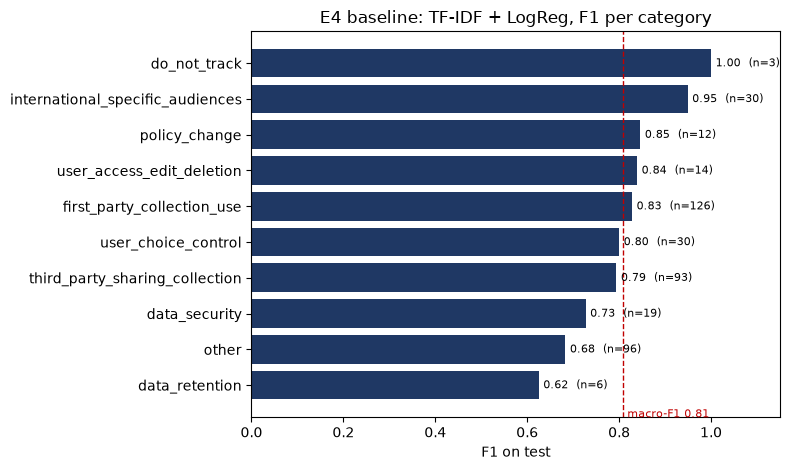

{
  "macro_f1_tuned": 0.8091,
  "micro_f1_tuned": 0.7909,
  "macro_f1_at_0.5": 0.8314,
  "micro_f1_at_0.5": 0.7958,
  "macro_f1_ci95_policy_bootstrap": [
    0.7617,
    0.8718
  ],
  "n_boot": 1000
}
Saved to: C:\Users\sweet\Downloads\opp115_package_tf\opp115_package\e4_output


In [7]:
order = metrics.sort_values("f1")
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(order.category, order.f1, color="#1F3864")
for y, (f1v, sp) in enumerate(zip(order.f1, order.test_support)):
    ax.text(f1v + 0.01, y, f"{f1v:.2f}  (n={sp})", va="center", fontsize=8)
ax.axvline(macro_f1, color="#C00000", linestyle="--", linewidth=1)
ax.text(macro_f1, -0.9, f" macro-F1 {macro_f1:.2f}", color="#C00000", fontsize=8)
ax.set_xlim(0, 1.15); ax.set_xlabel("F1 on test"); ax.set_title("E4 baseline: TF-IDF + LogReg, F1 per category")
plt.tight_layout(); plt.savefig(E4_DIR / "e4_tfidf_lr_per_class_f1.png", dpi=150); plt.show()

metrics.to_csv(E4_DIR / "e4_tfidf_lr_per_class_metrics.csv", index=False, encoding="utf-8-sig")
top_terms.to_csv(E4_DIR / "e4_tfidf_lr_top_terms.csv", index=False, encoding="utf-8-sig")
(E4_DIR / "e4_tfidf_lr_thresholds.json").write_text(json.dumps(thresholds, indent=2), encoding="utf-8")

pred_df = parts["test"][["policy_uid", "policy_file", "segment_id", "text"]].copy()
for j, c in enumerate(LABEL_COLS):
    pred_df["true_" + c] = Yte[:, j]; pred_df["prob_" + c] = Pte[:, j].round(4); pred_df["pred_" + c] = pred_tuned[:, j]
pred_df.to_csv(E4_DIR / "e4_tfidf_lr_test_predictions.csv", index=False, encoding="utf-8-sig")

summary = {
    "model": "TF-IDF (word 1-2gram, min_df=2, sublinear_tf) + One-vs-Rest LogisticRegression(class_weight=balanced, liblinear)",
    "selected_C": BEST_C, "c_search": search.to_dict("records"), "tfidf_features": int(Vtr.shape[1]),
    "excluded_no_majority": bool(EXCLUDE_NO_MAJORITY),
    "segments": {s: int(len(p)) for s, p in parts.items()}, "policies": {s: int(p.policy_uid.nunique()) for s, p in parts.items()},
    "test": {"macro_f1_tuned": round(macro_f1, 4), "micro_f1_tuned": round(micro_f1, 4),
             "macro_f1_at_0.5": round(macro_05, 4), "micro_f1_at_0.5": round(micro_05, 4),
             "macro_f1_ci95_policy_bootstrap": [round(ci[0], 4), round(ci[1], 4)], "n_boot": N_BOOT},
    "seed": SEED,
}
(E4_DIR / "e4_tfidf_lr_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
joblib.dump({"vectorizer": vec, "model": model, "label_cols": LABEL_COLS, "thresholds": T}, E4_DIR / "e4_tfidf_lr_model.joblib")

print(json.dumps(summary["test"], indent=2))
print("Saved to:", E4_DIR.resolve())